# Data to discoveries

Last time, we discussed the `NumPy` array, specifically `ndarray`. 

These are like lists in that they contain data, but an `ndarray` carries many different assumptions/restrictions.

Today, we will use two important Python packages:
- `pandas` : data wrangling 
- `MatplotLib` : data visualisation

Both are widely used with large communities.

In [ ]:
import pandas as pd
print(f"pandas version: {pd.__version__}")

## Pandas DataFrame

A `DataFrame` in pandas is a data structure that is a mix between:
- Python's `dict`
- NumPy's `ndarray`

The following data comes from CSO's 2022 census data on car ownership. (I got this data from CSO a few years ago, but now I cannot reproduce this.)

In [ ]:
# Numbers come from counties: Cork, Dublin, Fingal, Galway, Sligo
car_ownership = {
    "Population": [360152, 592713, 330506, 193323, 70198],
    "No cars": [10335, 69661, 10371, 5033, 3350],
    "One car": [44419, 84685, 44495, 23406, 10422],
    "Two cars": [50310, 34861, 36562, 27542, 9055],
    "Three cars": [11243, 6129, 6368, 5593, 1676],
    "Four or more cars": [4908, 1736, 1933, 2291, 567],
}

In [ ]:
print(car_ownership["Population"])
print(car_ownership["Population"][3])	# Population of Galway in 2022

This way of indexing is similar to how one does indexing for a `DataFrame`.

In [ ]:
df = pd.DataFrame(		# 'df' is a standard variable for a DataFrame
	car_ownership, 
	index=["Cork", "Dublin", "Fingal", "Galway", "Sligo"]
)
df

All `DataFrame`s have an `Index` which is the leftmost column. Default: `[0, 1, 2, ...]`

Think of a `DataFrame` as a spreadsheet, a table of data, and/or a collection of columns.

Each column is a `NumPy` array -- *therefore* each column has a **fixed** data type.

Different columns can have different data types (we will see examples soon).

In [ ]:
df["Population"]		# Grab a column

In [ ]:
df.loc["Galway"]		# Grab a row

In [ ]:
print(df["Population"]["Galway"])
# Notice the NumPy type in the output:
df["Population"]["Galway"] == df.loc["Galway"]["Population"]	

## UN's SDG data for Ireland

Let's load in UN data about Ireland from two files sources: 
- `data/01_below_poverty.csv`
- `data/06_sage_drinking_water.csv`
- `data/07_renewable_energy.csv`
- `data/08_NEET.csv`

This was obtained from the [United Nations' SDG Country Profile Page](https://unstats.un.org/sdgs/dataportal/countryprofiles/IRL)

### Below Poverty Data Set

We'll work through some of the basics with the below poverty data set.

Best way to get data into `pandas` is to use one of the many `pd.read_...` functions.

In [ ]:
df1 = pd.read_csv("data/01_below_poverty.csv")		# CSV to pandas DataFrame
df1.head()											# Display first 5 rows

Most of the columns look irrelevant. Let's look to keep the columns
- "TimePeriod"
- "Value"
- "Time_Detail"
- "[Age]"
- "[Location]"
- "[Sex]"

We'll select relevant columns by indexing with a list of column names.

In [ ]:
df1 = df1[[
	"TimePeriod",
	"Value",
	"Time_Detail",
	"[Age]",
	"[Location]",
	"[Sex]"
]]
df1

We need to clean our data before we can manipulate it. Let's remove the rows where `"TimePeriod"` is empty.

In [ ]:
df1 = df1.dropna(subset="TimePeriod")

We are not going to span the entirity of this data set. Let's just take the years 2005 to 2023.

We'll do this with the [query](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.query.html) command. 

At a basic level it takes a string that appropriately masks part of the dataframe.

By default, `query` is a copy, unlike slicing in `ndarray` which yields a view.

In [ ]:
df1 = df1.query("2005 <= TimePeriod <= 2023")

# Now more clean up
df1 = df1.drop(["Time_Detail"], axis=1)			# Useless column

df1

Now we are going to remove rows we don't have any need for; we give two equivalent ways to do this.

We'll use `query` again to obtain only the rows that are relevant.

In [ ]:
# df1 = df1[
# 	(df1["[Age]"] == "ALLAGE") & 
# 	(df1["[Location]"] == "ALLAREA") &
# 	(df1["[Sex]"] == "BOTHSEX")
# ]
df1 = (df1
    .query("`[Age]` == 'ALLAGE'")
    .query("`[Location]` == 'ALLAREA'")
    .query("`[Sex]` == 'BOTHSEX'")
)
df1

Some final touches.

In [ ]:
df1 = df1.drop(["[Age]", "[Location]", "[Sex]"], axis=1)
df1 = df1.set_index("TimePeriod")
df1 = df1.rename(columns={"Value" : "Below Poverty (%)"})
df1

### Speedrun the rest

We will basically do the same steps as above, but all at once. See if you can follow along line by line.

In [ ]:
df2 = pd.read_csv("data/07_renewable_energy.csv")
df2 = df2[["TimePeriod", "Value"]]
df2 = df2.dropna()
df2 = df2.set_index("TimePeriod")
df2 = df2.loc["2005":"2023"]
df2 = df2.rename(columns={"Value" : "Renewable Energy Share (%)"})
df2

In [ ]:
df3 = pd.read_csv("data/06_safe_drinking_water.csv")
df3 = df3[["TimePeriod", "Value", "[Location]"]]
df3 = df3.dropna()
df3 = df3.set_index("TimePeriod")
df3 = df3.loc["2005":"2024"]
df3 = df3.query("`[Location]` == 'ALLAREA'")
df3 = df3.drop("[Location]", axis=1)
df3 = df3.rename(columns={"Value" : "Safe Drinking Water by Pop. (%)"})
df3

In [ ]:
df4 = pd.read_csv("data/08_NEET.csv")
df4 = df4[["TimePeriod", "Value", "[Sex]"]]
df4 = df4.dropna()
df4 = df4.set_index("TimePeriod")
df4 = df4.loc["2005":"2024"]
df4 = df4.query("`[Sex]` == 'BOTHSEX'")
df4 = df4.drop("[Sex]", axis=1)
df4 = df4.rename(columns={"Value" : "NEETs aged 15-24 (%)"})
df4

## From two to one

Because our two DataFrames have the same index, we can concatenate them in `pandas`.

In [ ]:
df = pd.concat([df1, df2, df3, df4], axis=1)		# Merging our two DataFrames
df.index.names = ["Year"]							# Renaming the index
df

We can get some quick statistics on our data.

Using the `describe` method, we get the average and standard deviations.

In [ ]:
df.describe()

## Data visualization

We can now plot the DataFrame on a set of axes with `Matplotlib` (working in the background).

In [ ]:
_ = df.plot()		# Not super customisable
_ = df.plot(marker="o", linestyle="none")

[Matplotlib](https://matplotlib.org/) is a wonderful data visualisation package built on top of NumPy.

`pandas` is built on top of `Matplotlib`, and one can easily interact via `df.plot(...)`. 

I personally like to work directly with `Matplotlib`.

Let's look at all of the data we have here between 2005 and 2023.

In [ ]:
import matplotlib.pyplot as plt

COLOURS = ["#2225e6", "#e76532", "#e91717", "#1baf47"]	
MUTED = "#52514e"		# secondary text
GRID = "#e4e3df"		# faint gridlines

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, layout="constrained")
fig.suptitle("Ireland's UN SDG indicators", fontsize=16, fontweight="bold")

for ax, col, colour in zip(axes.flat, df.columns, COLOURS):
	s = df[col]
	ax.plot(s.index, s.values, color=colour, linewidth=2, marker="o", markersize=4)

	# Random settings to change the appearance. 
	ax.set_title(col, loc="left", fontsize=12, fontweight="bold")
	ax.grid(color=GRID, linewidth=0.8)	# horizontal and vertical gridlines
	ax.set_axisbelow(True)
	ax.spines[["top", "right", "left"]].set_visible(False)
	ax.tick_params(colors=MUTED, length=0)
	ax.set_ylabel("%", color=MUTED)
	ax.set_xticks(range(2005, 2024, 3))	# 2005, 2008, ..., 2023

plt.show()

## Data for all countries

Let's look at (nearly) all countries' data for the UN SDG goals from above. 

In [ ]:
# Need openpyxl to read xlsx files
df1 = pd.read_excel("data/Goal1.xlsx")
df6 = pd.read_excel("data/Goal6.xlsx")
df7 = pd.read_excel("data/Goal7.xlsx")
df8 = pd.read_excel("data/Goal8.xlsx")

### How does Ireland compare?

These files hold the same four indicators as before, but for (almost) every country. 

Each file also mixes several breakdowns (by age, sex, urban/rural, ...), so we keep only the rows that match what we used for Ireland.

We write a small function to do the filtering, then glue the four results together side by side, just like we did with `pd.concat` earlier. 

The index now has *two* levels: `Country` and `Year`.

In [ ]:
def extract(data, name, **filters):
	for column, value in filters.items():
		data = data[data[column] == value]
	s = data.set_index(["GeoAreaName", "TimePeriod"])["Value"]
	s.index.names = ["Country", "Year"]
	return s.rename(name)

Now we'll use `extract` to get all the data we need.

In [ ]:
world = pd.concat([
	extract(df1, "Below Poverty (%)", SeriesCode="SI_POV_DAY1", Age="ALLAGE", Location="ALLAREA", Sex="BOTHSEX"),
	extract(df7, "Renewable Energy Share (%)"),
	extract(df6, "Safe Drinking Water by Pop. (%)", Location="ALLAREA"),
	extract(df8, "NEETs aged 15-24 (%)", SeriesCode="SL_TLF_NEET", Sex="BOTHSEX"),
], axis=1).sort_index()
world

Sanity check: the rows for Ireland should match our `df` from earlier.

In [ ]:
world.loc["Ireland"]		# Grabbing the data associated with Ireland

In [ ]:
world.xs(2022, level="Year")	# Grabbing the data associated with 2022

Next we form three groups for comparison.

- **EU**: the other 26 member states.
- **Small advanced economies**: the countries in the Small Advanced Economies Initiative, which Ireland belongs to.
- **World**: every other country in the data.

The lists are only a starting point. (Try adding or removing countries or creating your own lists!)

In [ ]:
groups = {
	"EU": [
		"Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus", "Czechia", "Denmark",
		"Estonia", "Finland", "France", "Germany", "Greece", "Hungary", "Italy",
		"Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands (Kingdom of the)",
		"Poland", "Portugal", "Romania", "Slovakia", "Slovenia", "Spain", "Sweden",
	],
	"Small adv. econs": [
		"Denmark", "Finland", "Israel", "New Zealand", "Singapore", "Switzerland",
	],
	"World": list(world.index.unique("Country").drop("Ireland")),
}

Countries report in different years, so we take a *snapshot*: each country's most recent value from 2018–2023.

`groupby("Country").last()` does exactly this. Within each country it takes the last value in each column, skipping any `NaN`s.

Breaking it down:
- `groupby("Country")` returns a `GroupBy` object which treats each country's rows as a group that one can call methods on,
- `last()` is a method that simply grabs the last (i.e. most recent), non-empty entry 

In [ ]:
latest = (world
          .query("2018 <= Year <= 2023")
		  .groupby("Country")
		  .last()
)
latest

Now for each group and indicator we work out:
- the group's median,
- Ireland's rank within the group, plus Ireland (1 = best).

For poverty and NEETs, *lower* is better, so we rank in ascending order for those.

In [ ]:
lower_is_better = ["Below Poverty (%)", "NEETs aged 15-24 (%)"]

rows = []
for group, peers in groups.items():
	# Restrict countries to the group
	table = latest.loc[latest.index.isin(peers + ["Ireland"])]
	for indicator in latest.columns:
		values = table[indicator].dropna()
		rank = values.rank(
			ascending=bool(indicator in lower_is_better), 
			method="min"
		)
		rows.append({
			"Indicator": indicator,
			"Group": group,
			"Ireland": values["Ireland"],
			"Group median": values.drop("Ireland").median(),
			"Ireland's rank": f"{rank['Ireland']:.0f} of {len(values)}",
		})

summary = pd.DataFrame(rows).set_index(["Indicator", "Group"])
summary.round(1)

This summary is already quite informative.

We get a different angle on the data by visualising.

In [ ]:
import numpy as np

IRELAND = "#E28102"		# Ireland's highlight colour
OTHERS = "#2A19EA"			# every other country
MEDIAN = "#202021"			# secondary text
MUTED = "#52514e"			# secondary text
GRID = "#e4e3df"			# faint gridlines

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharey=True, layout="constrained")
fig.suptitle("Ireland compared to peers", fontsize=16, fontweight="bold")

for ax, indicator in zip(axes.flat, latest.columns):
	for row, (group, peers) in enumerate(groups.items()):
		values = latest.loc[latest.index.isin(peers), indicator].dropna()
		# noise so they don't all overlap
		jitter = np.random.default_rng(42).uniform(-0.15, 0.15, len(values))

		# Plots
		ax.scatter(values, row + jitter, s=18, color=OTHERS, alpha=0.7, linewidths=0)									 # other countries
		ax.plot([values.median()] * 2, [row - 0.3, row + 0.3], color=MEDIAN, linewidth=2)									  # group median
		ax.scatter(latest.loc["Ireland", indicator], row, s=90, color=IRELAND, edgecolors="black", linewidths=0.5, zorder=3)	# Ireland

	ax.set_title(indicator, loc="left", fontsize=12, fontweight="bold")
	ax.set_yticks(range(len(groups)), groups.keys())
	ax.grid(axis="x", color=GRID, linewidth=0.8)
	ax.set_axisbelow(True)
	ax.spines[["top", "right", "left"]].set_visible(False)
	ax.tick_params(colors=MUTED, length=0)

axes[0, 0].invert_yaxis()		# first group at the top (y-axis is shared, so flip it once)

fig.get_layout_engine().set(hspace=0.15)	# breathe!

# A legend built by hand, since the same three marks repeat in every panel
fig.legend(
	handles=[
		plt.Line2D([], [], marker="o", linestyle="", markersize=9, color=IRELAND, label="Ireland"),
		plt.Line2D([], [], marker="o", linestyle="", markersize=5, color=OTHERS, label="Other countries"),
		plt.Line2D([], [], marker="|", linestyle="", markersize=12, markeredgewidth=2, color=MEDIAN, label="Group median"),
	],
	loc="outside lower center", ncols=3, frameon=False,
)
plt.show()

### Renewable energy across Europe (another perspective!)

Let's zoom in on one indicator: the share of final energy consumption that comes from renewables.

**Question:** which European countries have made the most progress since 2005, and where does Ireland fit?

In [ ]:
europe = groups["EU"] + [
	"Ireland", "United Kingdom of Great Britain and Northern Ireland",
	"Iceland", "Norway", "Switzerland",
	"Albania", "Bosnia and Herzegovina", "Kosovo", "Montenegro", "North Macedonia", "Serbia",
	"Belarus", "Republic of Moldova", "Ukraine",
]

`world` is *long*: one row per (country, year). To compare years side by side we want it *wide*: one row per country and one column per year.

`unstack("Year")` does this by moving the `Year` level of the index into the columns. Some years have no European data at all, so we drop columns that are entirely `NaN`.

In [ ]:
renewables = (world
	.loc[europe, "Renewable Energy Share (%)"]		# European rows, one column
	.unstack("Year")								# Put year to columns
	.dropna(axis=1, how="all")						# Drop years with no data
	.rename(index={									# Some names...
		"United Kingdom of Great Britain and Northern Ireland": "United Kingdom",
		"Netherlands (Kingdom of the)": "Netherlands",
	})
)
renewables

We won't do too much with this lovely matrix. We determine two values from 2005 to 2023:
1. **Points gained** : the absolute change in percentage points.
2. **Growth factor** : the relative change (dimensionless).

Each column is a NumPy array, so each measure takes one line of arithmetic and no loops.

In [ ]:
progress = pd.DataFrame({
	"2005": renewables[2005],
	"2023": renewables[2023],
})
# progress

# Values
progress["Points gained"] = progress["2023"] - progress["2005"]
progress["Growth factor"] = progress["2023"] / progress["2005"]

progress = progress.sort_values("Points gained", ascending=False)
progress.round(1)

The two measures tell different stories. `rank` turns each column into positions (1 = most progress).

In [ ]:
ranks = progress[["Points gained", "Growth factor"]].rank(ascending=False).astype(int)
ranks.loc[["Ireland", "Malta", "Norway", "Montenegro"]]

- **Ireland** is mid-table on points gained (16th of 40) but 7th on growth: its share grew more than fivefold, from a very low base.
- **Malta** is 1st on growth because it started at 0.14%. A tiny starting value makes a ratio look huge. This is a common way relative change misleads.
- **Norway** is near the bottom on both, but it was already at about 60% in 2005, so there was little room to grow.
- **Montenegro** is one of only two countries whose share *fell*.

Which measure is "right" depends on the question you are asking.

A *dumbbell chart* shows both years at once: a grey dot for 2005, a coloured dot for 2023, and a line joining them. Countries are sorted by their 2023 share.

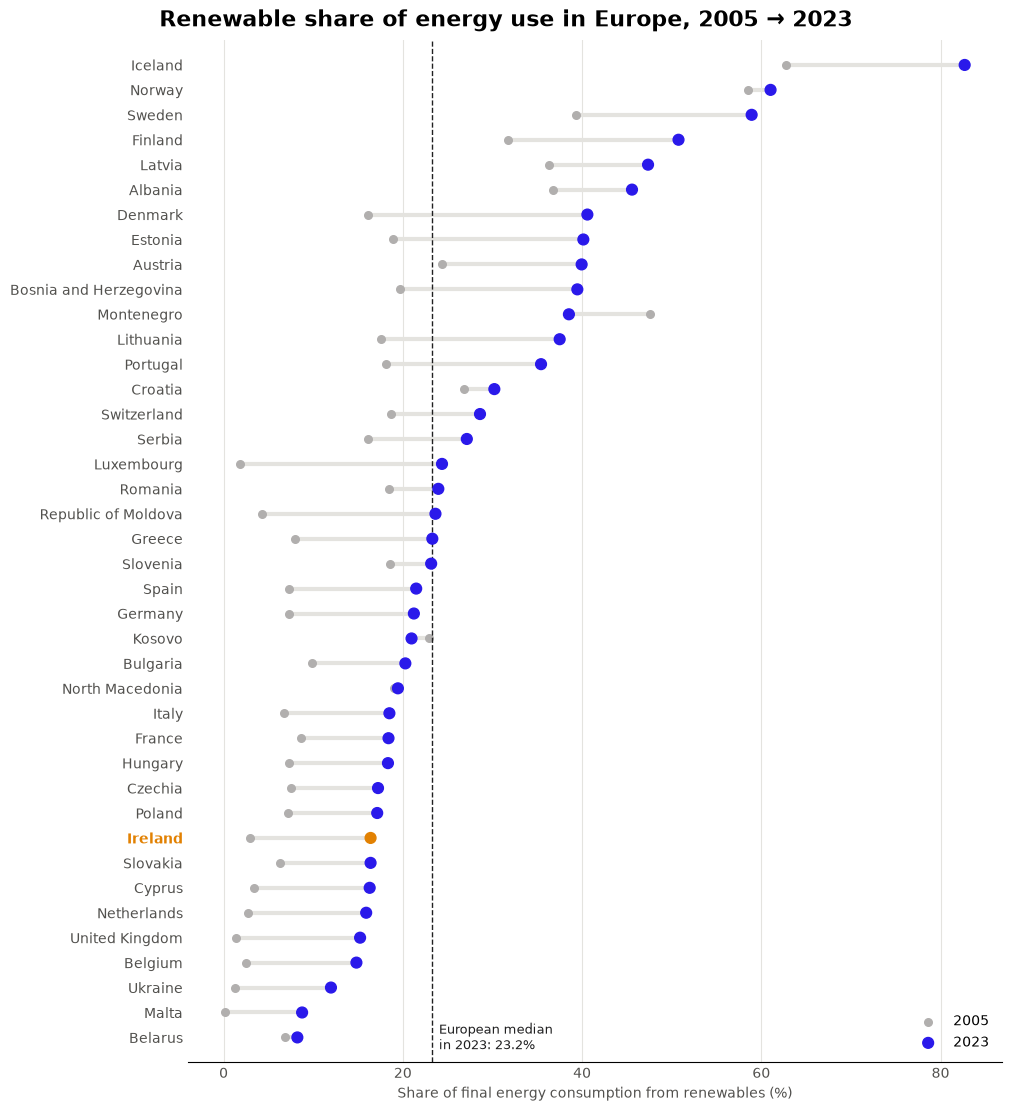

In [ ]:
progress = progress.sort_values("2023")
median_2023 = progress["2023"].median()
EARLY = "#B1AFAE"		# colour of the 2005 dots

fig, ax = plt.subplots(figsize=(10, 11), layout="constrained")
fig.suptitle("Renewable share of energy use in Europe, 2005 → 2023", fontsize=16, fontweight="bold")

y = range(len(progress))
colours = [IRELAND if c == "Ireland" else OTHERS for c in progress.index]
ax.hlines(y, progress["2005"], progress["2023"], color=GRID, linewidth=3, zorder=1)	# the bar of each dumbbell
ax.scatter(progress["2005"], y, s=30, color=EARLY, zorder=2, label="2005")
ax.scatter(progress["2023"], y, s=60, color=colours, zorder=3, label="2023")
ax.axvline(median_2023, color=MEDIAN, linestyle="--", linewidth=1)
ax.text(median_2023 + 0.8, 0, f"European median\nin 2023: {median_2023:.1f}%", color=MEDIAN, fontsize=9, va="center")

ax.set_yticks(y, progress.index)
ax.set_ylim(-1, len(progress))
ax.set_xlabel("Share of final energy consumption from renewables (%)", color=MUTED)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
ax.legend(loc="lower right", frameon=False)

# Make Ireland's label stand out 
for label in ax.get_yticklabels():
	if label.get_text() == "Ireland":
		label.set_color(IRELAND)
		label.set_fontweight("bold")

plt.show()